## Data Anaysis of the MuSe dataset 

For each datapoint consists of an metadata of an audio track and an three-dimenional emotional score.

$\mathbb{D}_{muse} = \{(x_i,t_i)\}_{i=1}^{N}$



Where : 
- $x_i$ is the metadata of the track 
- $t_i$ is Valence, Arousal and Dominance score of the track

In [18]:
# Imports
import pandas as pd
import random as r
import matplotlib.pyplot as plt
import numpy as np

In [108]:
df = pd.read_csv("../../datasets\muse/muse_v3.csv")

In [6]:
df[:5]

,lastfm_url,track,artist,seeds,number_of_emotion_tags,valence_tags,arousal_tags,dominance_tags,mbid,spotify_id,genre
0,https://www.last.fm/music/eminem/_/%2527till%2...,'Till I Collapse,Eminem,['aggressive'],6,4.550000,5.273125,5.690625,cab93def-26c5-4fb0-bedd-26ec4c1619e1,4xkOaSrkexMciUUogZKVTS,rap
1,https://www.last.fm/music/metallica/_/st.%2banger,St. Anger,Metallica,['aggressive'],8,3.710000,5.833000,5.427250,727a2529-7ee8-4860-aef6-7959884895cb,3fOc9x06lKJBhz435mInlH,metal
2,https://www.last.fm/music/rick%2bross/_/speedi...,Speedin',Rick Ross,['aggressive'],1,3.080000,5.870000,5.490000,NaN,3Y96xd4Ce0J47dcalLrEC8,rap
3,https://www.last.fm/music/m.i.a./_/bamboo%2bbanga,Bamboo Banga,M.I.A.,"['aggressive', 'fun', 'sexy', 'energetic']",13,6.555071,5.537214,5.691357,99dd2c8c-e7c1-413e-8ea4-4497a00ffa18,6tqFC1DIOphJkCwrjVzPmg,hip-hop
4,https://www.last.fm/music/dope/_/die%2bmf%2bdie,Die MF Die,Dope,['aggressive'],7,3.771176,5.348235,5.441765,b9eb3484-5e0e-4690-ab5a-ca91937032a5,5bU4KX47KqtDKKaLM4QCzh,metal


In [7]:
print(f"{df.shape=}\n" \
f"{df.columns.tolist()=}\n"\
f"{df.isnull().sum()=}")

df.shape=(90001, 11)
df.columns.tolist()=['lastfm_url', 'track', 'artist', 'seeds', 'number_of_emotion_tags', 'valence_tags', 'arousal_tags', 'dominance_tags', 'mbid', 'spotify_id', 'genre']
df.isnull().sum()=lastfm_url                    0
track                         0
artist                        0
seeds                         0
number_of_emotion_tags        0
valence_tags                  0
arousal_tags                  0
dominance_tags                0
mbid                      28784
spotify_id                28371
genre                      6639
dtype: int64


In [ ]:
df["genre"] = df["genre"].fillna("Unknown")

### Prompt Builder

In [9]:
df["prompt"] = (
    "Track: " + df["track"].astype(str) + 
    "| Artist: " + df["artist"].astype(str) + 
    "| Genre: " + df["genre"].astype(str)
)

In [93]:
df["valence_01"] = (
    (df["valence_tags"] - df["valence_tags"].min()) /
    (df["valence_tags"].max() - df["valence_tags"].min())
)

df["arousal_01"] = (
    (df["arousal_tags"] - df["arousal_tags"].min()) /
    (df["arousal_tags"].max() - df["arousal_tags"].min())
)

df["dominance_01"] = (
    (df["dominance_tags"] - df["dominance_tags"].min()) /
    (df["dominance_tags"].max() - df["dominance_tags"].min())
)

In [94]:
df["vad"] = df[
    ["valence_tags", "arousal_tags", "dominance_tags"]
].values.tolist()
df["vad_01"] = df[
    ["valence_01", "arousal_01", "dominance_01"]
].values.tolist()

In [95]:
i = r.randint(0,len(df))
print(i)

df[["prompt", "valence_tags", "arousal_tags", "dominance_tags"]][i:i+5]

34868


,prompt,valence_tags,arousal_tags,dominance_tags
34868,Track: The Temple Of Vaal| Artist: David Arken...,6.374928,3.552899,5.797826
34869,Track: Rising| Artist: Greg Maroney| Genre: piano,7.185833,4.376667,6.410000
34870,Track: With a Little Patience| Artist: Eleven ...,6.335000,4.325000,6.075000
34871,Track: Nearer My God to Thee| Artist: The Pian...,5.820000,4.820000,6.300000
34872,Track: Nostrie Tiempo| Artist: Marcomé| Genre:...,5.940000,3.428000,5.888250


In [100]:
safe_cols = [
    "prompt",
    "valence_tags",
    "arousal_tags",
    "dominance_tags"
]

if df.duplicated(subset=safe_cols).all():
    print("There are Duplicates")
else:
    print("There are No Duplicates")

There are No Duplicates


## Plotting


In [ ]:
class Plot:
    def __init__(self, df):
        self.df = df

    def _plot_distrbution(
            self,
            col: str,
            bins: int = 50,
            save_dir: str = "../../plots/muse/dataset",
            hist: bool = False,
            prob_dist: bool = False) -> None:
        
        data = self.df[col].dropna()
        
        if prob_dist == True:
            data = (data - data.min()) / (data.max() - data.min())

        mu = data.mean()
        sigma = data.std()

        plt.figure(figsize=(10,6))

        if hist == True: 
            plt.hist(data, bins=bins, density=True, alpha=0.7)

        x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 1000)

        gaussian = (
            1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
                -0.5 * ((x - mu) / sigma) ** 2
            )
        
        label_case = col.replace("_", " ").title()

        if prob_dist == True:
            label_case += " (Scaled to 0 - 1)"


        plt.plot(x, gaussian, label=fr"$\mu={mu:.3f},\ \sigma={sigma:.3f}$")
        plt.title(f"Distribution of {label_case}")
        label_case = label_case.replace(" (Scaled to 0 - 1)", "")
        plt.xlabel(label_case)
        plt.ylabel("Density")
        plt.legend()


        snake_case = f"distribution_of_{col}".lower().replace(" ", "_")
        save_path = f"{save_dir}/{snake_case}.png"

        if prob_dist == True:
            snake_case += "_scaled_to_0-1"

        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        plt.show()

    def valence_dist(self, hist: bool = False, prob_dist: bool = False) -> None: self._plot_distrbution("valence_tags", hist=hist, prob_dist=prob_dist)

    def arousal_dist(self, hist: bool = False, prob_dist: bool = False) -> None: self._plot_distrbution("arousal_tags", hist=hist, prob_dist=prob_dist)

    def dominance_dist(self, hist: bool = False, prob_dist: bool = False) -> None: self._plot_distrbution("dominance_tags", hist=hist, prob_dist=prob_dist)


In [87]:
plot = Plot(df)

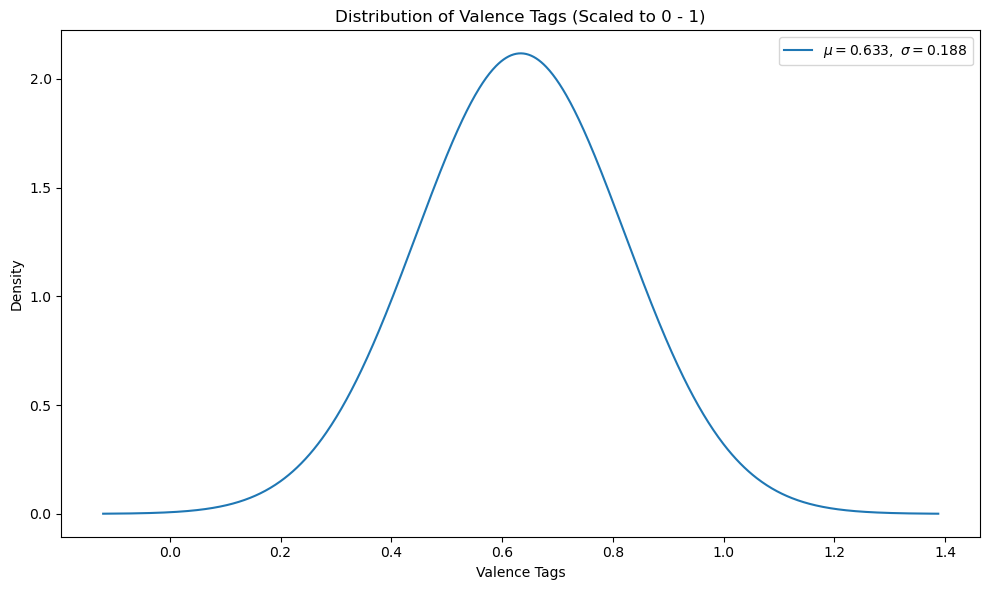

In [88]:
plot.valence_dist(prob_dist=True)

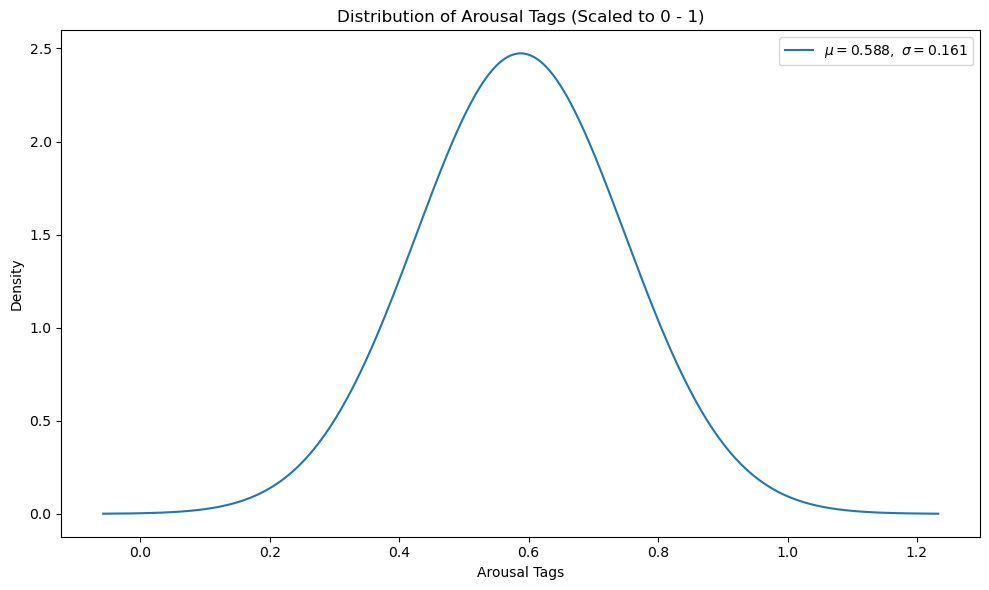

In [84]:
plot.arousal_dist(prob_dist=True)


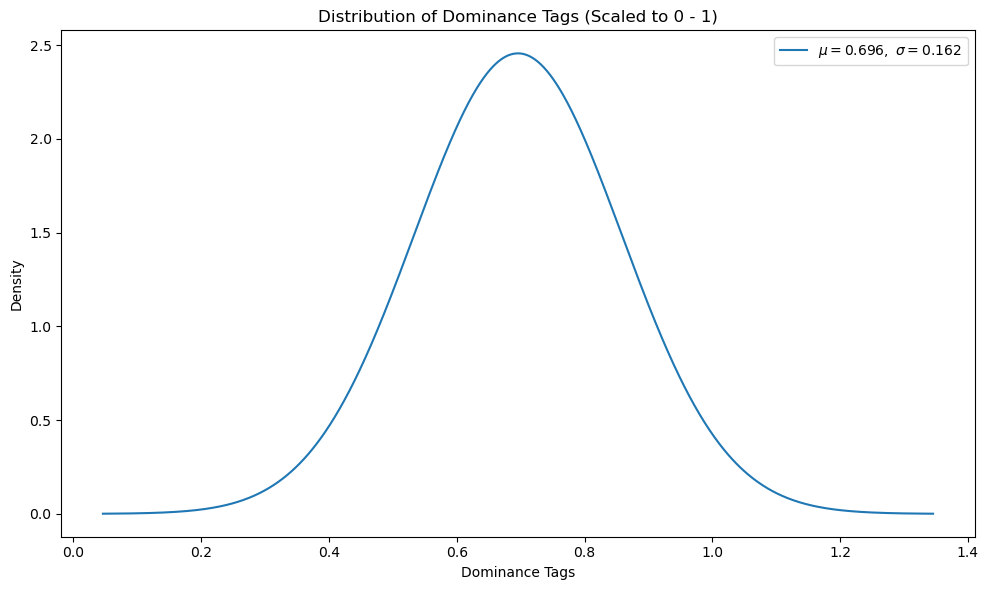

In [82]:
plot.dominance_dist(prob_dist=True)


### Saving the Modified Dataset

In [101]:
bert_df = df[["prompt", "vad", "vad_01"]].copy()

In [102]:
bert_df.head()

,prompt,vad,vad_01
0,Track: 'Till I Collapse| Artist: Eminem| Genre...,"[4.55, 5.273124999999999, 5.690625]","[0.5236650485436892, 0.7211803177195848, 0.757..."
1,Track: St. Anger| Artist: Metallica| Genre: metal,"[3.71, 5.832999999999999, 5.427250000000002]","[0.4217233009708738, 0.7993545497655302, 0.720..."
2,Track: Speedin'| Artist: Rick Ross| Genre: rap,"[3.08, 5.87, 5.49]","[0.3452669902912622, 0.8045207861320407, 0.729..."
3,Track: Bamboo Banga| Artist: M.I.A.| Genre: hi...,"[6.555071428571428, 5.537214285714287, 5.69135...","[0.7669989597780859, 0.7580545791212847, 0.757..."
4,Track: Die MF Die| Artist: Dope| Genre: metal,"[3.771176470588235, 5.348235294117648, 5.44176...","[0.42914762992575667, 0.7316678186106628, 0.72..."


In [107]:
bert_df.to_csv("../../datasets\muse/modified/bert_df.csv", index=False)
bert_df.to_parquet("../../datasets\muse/modified/bert_df.parquet", index=False)